<font size = "6"> TP noté - Algorithmique des graphes </font>

Documents de cours autorisés. Vous avez le droit d'aller sur les sites de la documentation sagemath (lien ci-dessous) mais ce sont les seuls autorisés.

Durée 2h00

In [ ]:
from sage.graphs.graph_plot import GraphPlot

https://doc.sagemath.org/html/en/reference/graphs/sage/graphs/generic_graph.html

https://doc.sagemath.org/html/en/reference/graphs/sage/graphs/digraph.html

# Exercice 1

1. On se donne la matrice suivante qui est la matrice d'adjacence d'un graphe. Donner le graphe en question.

In [ ]:
M = Matrix([[0,1,0,0,1,0,0,0],[0,0,1,1,0,0,0,0],[1,0,0,0,0,0,0,0],[0,0,0,0,1,0,0,0],[0,0,0,1,0,1,1,0],[0,0,0,0,0,0,1,0],[0,0,0,0,0,0,0,1],[0,0,0,0,0,1,0,0]])
M

[0 1 0 0 1 0 0 0]
[0 0 1 1 0 0 0 0]
[1 0 0 0 0 0 0 0]
[0 0 0 0 1 0 0 0]
[0 0 0 1 0 1 1 0]
[0 0 0 0 0 0 1 0]
[0 0 0 0 0 0 0 1]
[0 0 0 0 0 1 0 0]

2. Quelles sont les composantes fortement connexes de ce graphe ? <br>

In [1]:
from sage.graphs.digraph import DiGraph
G1 = DiGraph(M)
print("Composantes fortement connexes de G:", G1.strongly_connected_components())

NameError: name 'DiGraph' is not defined

3. On affichera le graphe avec un coloriage des sommets en fonction de la composante fortement connexe dont il fait partie. Le graphe suivant vous servira d'exemple pour comprendre comment faire un coloriage des sommets :

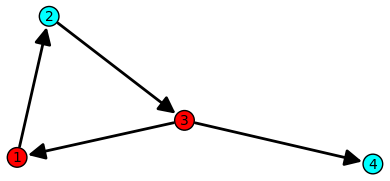

In [ ]:
Gex = DiGraph([(1,2), (2,3), (3, 1), (3, 4)])
Gex.show(partition = ([1, 3], [2, 4]))

In [2]:
from sage.graphs.digraph import DiGraph
G1 = DiGraph(M)
scc = G1.strongly_connected_components()
G1.show(partition=scc)

NameError: name 'G1' is not defined

4. Ecrire une fonction qui étant donné un graphe G, deux sommets a et b et un entier k, renvoie le nombre de chemins de longueur k entre a et b, ainsi que la liste de ces chemins. <br>
Pour la liste des chemins, on ira voir la documentation des fonctions
https://doc.sagemath.org/html/en/reference/graphs/sage/graphs/path_enumeration.html <br>
Donner un exemple d'utilisation de la fonction.

In [3]:
def chemins_longueur_k(G, a, b, k):
    all_paths = list(G.all_paths(a, b, simple=False))
    paths_k = [p for p in all_paths if len(p) - 1 == k]
    return len(paths_k), paths_k

In [4]:
from sage.graphs.digraph import DiGraph
G1 = DiGraph(M)
nb, chemins = chemins_longueur_k(G1, 0, 3, 3)
print(f"Nombre de chemins de longueur 3 entre 0 et 3 : {nb}")
print(f"Liste des chemins : {chemins}")

NameError: name 'G1' is not defined

# Exercice 2

On se donne le graphe ci-dessous

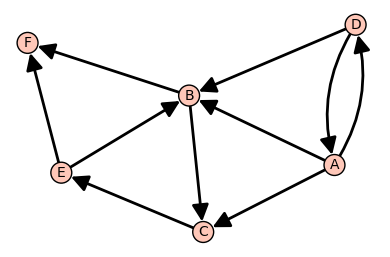

In [ ]:
G = DiGraph([('A','D'), ('A', 'C'), ('A', 'B'), ('D', 'A'), ('D', 'B'), ('C', 'E'),
            ('B', 'F'), ('E', 'F'), ('B', 'C'), ('E', 'B')])
G.show()

1. Donner sa représentation par liste d'adjacence.

In [5]:
from sage.graphs.digraph import DiGraph
G = DiGraph([('A','D'), ('A', 'C'), ('A', 'B'), ('D', 'A'), ('D', 'B'), ('C', 'E'), ('B', 'F'), ('E', 'F'), ('B', 'C'), ('E', 'B')])
for v in sorted(G.vertices()):
    print(f"{v} -> {sorted(G.neighbors_out(v))}")

NameError: name 'G' is not defined

2. Quel serait l'ordre de parcours des sommets si on part de A, procède à l'algorithme de parcours en profondeur, et qu'on fait le choix de parcours dans l'ordre alphabétique.

L'ordre de parcours en profondeur (DFS) en partant de **A** avec choix alphabétique est :
**A -> B -> C -> E -> F -> D**

- Depuis A, on visite B (ordre alphabétique entre B, C, D).
- Depuis B, on visite C (ordre alphabétique entre C, F).
- Depuis C, on visite E.
- Depuis E, on visite F (car B est déjà visité).
- Depuis F, pas de successeur non visité, on retourne à E, B, A.
- Depuis A, on visite D.

3. Même question pour le parcours en largeur.

L'ordre de parcours en largeur (BFS) en partant de **A** avec choix alphabétique est :
**A -> B -> C -> D -> F -> E**

- Niveau 0 : A
- Niveau 1 : B, C, D (voisins directs de A dans l'ordre alphabétique)
- Niveau 2 : Depuis B, on ajoute F. Depuis C, on ajoute E. Depuis D, aucun nouveau voisin.

4. Même question que la 3. mais en partant du sommet B. Est-ce que l'on voit tous les sommets ? Qu'est-ce que cela nous apprend du graphe ?

En partant du sommet **B** :
- **Parcours BFS** : **B -> C -> F -> E**
- **Sommets non visités** : A et D ne sont pas visités car il n'existe aucun chemin orienté menant de B à A ou de B à D.
- **Conclusion** : Le graphe n'est pas fortement connexe.

# Exercice 3
On se propose de modéliser le déplacement du cavalier dans un échiquier $n\times n$ (avec $n\geq 3$) sans utiliser la fonction <tt>KnightGraph</tt> de Sagemath. On rappelle les déplacements du cavalier :

https://www.creachess.com/cours/imgs/deplacement-cavalier.jpg

1. Donner une fonction qui étant donné un entier n, donne le graphe de déplacement du cavalier sur l'échiquier (n, n), accessible depuis la case A1. Vous expliquerez votre modélisation.

In [6]:
from sage.graphs.graph_generators import graphs
def graphe_cavalier(n):
    G_all = graphs.KnightGraph([n, n])
    comp = G_all.connected_component_containing_vertex((0, 0))
    return G_all.subgraph(vertices=comp)

2. Afficher le graphe pour n = 6 et n = 3, en mettant chaque noeud aux coordonnées de sa case. Autrement dit les noeuds seront une grille et les arêtes les déplacements de cavalier. <br>

On rappelle que c'est la fonction graphplot qui permet de bien positionner les noeuds :
https://doc.sagemath.org/html/en/reference/plotting/sage/graphs/graph_plot.html

In [7]:
from sage.graphs.graph_generators import graphs
for n_val in [3, 6]:
    G_c = graphe_cavalier(n_val)
    pos = {v: [v[0], v[1]] for v in G_c.vertices()}
    print(f"Graphe du cavalier pour n = {n_val}")
    G_c.show(pos=pos, vertex_size=300)

NameError: name 'Graphs' is not defined

3. Pour n allant de 3 à 8, donner la distance maximale entre deux sommets, dire une paire qui réalise cette distance maximale, et une chaîne pour aller de l'un à l'autre de longueur minimale

In [8]:
from sage.graphs.graph_generators import graphs
for n in range(3, 9):
    G_c = graphe_cavalier(n)
    diam = G_c.diameter()
    found = False
    for u in G_c.vertices():
        for v in G_c.vertices():
            if G_c.distance(u, v) == diam:
                paire = (u, v)
                chemin = G_c.shortest_path(u, v)
                found = True
                break
        if found: break
    print(f"n={n} | Distance max: {diam} | Paire: {paire} | Chemin min: {chemin}")

NameError: name 'Graphs' is not defined

# Exercice 4

On se donne les phrases suivantes, numérotées et mises dans un dictionnaire.

In [ ]:
d = {1 : "je aime beaucoup algorithmique des graphes",
     2 : "je aime beaucoup algorithmique",
     3 : "je fais algorithmique",
     4 : "je dessine des graphes",
     5 : "je dessine une maison",
     6 : "je mange à la maison",
     7 : "je fais un hamburger maison",
     8 : "je cours vers la maison",
     9 : "ce contrôle de algorithmique est trop dur",
     10 : "je révise algorithmique à la maison",
     11 : "je étudie les graphes",
     12 : "I speak english very well",
     13 : "je cours et je révise",
     14 : "je vais en cours aujourd'hui encore",
     15 : "je conduis une Mégane"
    }

En traitement automatique du langage, on étudie les liens entre les phrases. Notre but ici sera de créer un graphe où chaque sommet est une phrase, et les phrases sont reliées entre elles si elles ont un mot en commun (ou plus)

Bien sûr seuls les mots signifiant seront pris en compte. Dans notre cas, par simplification, on dira qu'il s'agit des mots de longueur au moins 4.

On pourra utiliser la méthode <tt>split</tt> qui divise un string en la liste de ses mots.

1. Créer le graphe en question

In [9]:
from sage.graphs.graph import Graph
G_phrases = Graph()
for k in d.keys():
    G_phrases.add_vertex(k)

mots_par_phrase = {}
for k, phrase in d.items():
    mots = set([w.lower() for w in phrase.split() if len(w) >= 4])
    mots_par_phrase[k] = mots

for u in d.keys():
    for v in d.keys():
        if u < v:
            if mots_par_phrase[u].intersection(mots_par_phrase[v]):
                G_phrases.add_edge(u, v)

NameError: name 'Graph' is not defined

2. Afficher ce graphe en plaçant les sommets en cercle

In [10]:
from sage.graphs.graph import Graph
if 'G_phrases' not in globals():
    G_phrases = Graph()
    for k in d.keys():
        G_phrases.add_vertex(k)
    mots_par_phrase = {}
    for k, phrase in d.items():
        mots = set([w.lower() for w in phrase.split() if len(w) >= 4])
        mots_par_phrase[k] = mots
    for u in d.keys():
        for v in d.keys():
            if u < v:
                if mots_par_phrase[u].intersection(mots_par_phrase[v]):
                    G_phrases.add_edge(u, v)
G_phrases.show(layout='circular')

NameError: name 'G_phrases' is not defined

3. Que dire des sommets 12 et 15 ? Pourquoi ?

- **Sommets 12 et 15** : Ce sont des sommets isolés (de degré 0).
- **Pourquoi** :
  - Pour la phrase 12 ("I speak english very well"), les mots significatifs (longueur >= 4) sont `['speak', 'english', 'very', 'well']`. Aucun de ces mots n'apparaît dans les autres phrases.
  - Pour la phrase 15 ("je conduis une Mégane"), les mots significatifs sont `['conduis', 'mégane']`, qui n'apparaissent nulle part ailleurs.

4. Voyez-vous une/des limite(s) au modèle proposé aujourd'hui ?

### Limites du modèle :
1. **Faux positifs syntaxiques** : Le modèle relie des phrases partageant des homonymes ou des mots fonctionnels de plus de 4 lettres sans rapport sémantique réel.
2. **Absence de lemmatisation** : Les mots fléchis (ex: conjugaisons, singulier/pluriel comme 'graphe' et 'graphes') ne sont pas reconnus comme identiques s'ils n'ont pas exactement la même orthographe.
3. **Seuil arbitraire de longueur** : Exclure les mots de moins de 4 lettres peut faire rater des mots sémantiquement riches de 3 lettres (ex: 'col', 'but', 'roi').

5. Quel est la phrase ayant le plus de mots communs avec les autres phrases ? Faites un programme pour le montrer.

In [11]:
from sage.graphs.graph import Graph
if 'G_phrases' not in globals():
    G_phrases = Graph()
    for k in d.keys():
        G_phrases.add_vertex(k)
    mots_par_phrase = {}
    for k, phrase in d.items():
        mots = set([w.lower() for w in phrase.split() if len(w) >= 4])
        mots_par_phrase[k] = mots
    for u in d.keys():
        for v in d.keys():
            if u < v:
                if mots_par_phrase[u].intersection(mots_par_phrase[v]):
                    G_phrases.add_edge(u, v)
degres = G_phrases.degree_dict()
max_deg = max(degres.values())
phrases_max = [k for k, v in degres.items() if v == max_deg]
print(f"Degré maximum de connexion : {max_deg}")
for p in phrases_max:
    print(f"Phrase {p} : \"{d[p]}\"")

NameError: name 'G_phrases' is not defined

# Exercice 5
On donne les trois fonctions mystères suivantes ainsi que les deux exemples d'utilisation.

In [ ]:
def mystere2(L):
    for i in range(1, max(L)):
        if i not in L:
            return i
    return max(L) + 1

In [ ]:
def mystere3(d):
    M = max(d.values())
    L = []
    for i in range(M):
        L.append([])
    for j in d:
        L[d[j]-1].append(j)
    return L

In [ ]:
def mystere1(G,s):
    dvu={}
    c = {}
    for i in G:
        dvu[i]=False
        c[i] = 0
    P = [s]
    dvu[s] = True
    c[s] = 1
    while len(P)!=0:
        som = P[-1]
        trouve = False
        for i in G.neighbors(som):
            L = []
            for j in G.neighbors(i):
                if c[j] not in L:
                    L.append(c[j])
            c[i] = mystere2(L)
            if trouve==False:
                if dvu[i] == False:
                    P.append(i)
                    dvu[i] = True
                    trouve = True
        if trouve == False:
            P.pop()
    return c

In [ ]:
pos_dict = {0: [0.0, 1.0], 1: [-0.5877852522924731, 0.8090169943749475], 2: [-0.9510565162951535, 0.30901699437494745], 3: [-0.9510565162951535, -0.30901699437494745], 4: [-0.5877852522924731, -0.8090169943749475], 5: [0.0, -1.0], 6: [0.5877852522924731, -0.8090169943749475], 7: [0.9510565162951535, -0.30901699437494745], 8: [0.9510565162951535, 0.30901699437494745], 9: [0.5877852522924731, 0.8090169943749475], 10: [0.0, 0.5], 11: [-0.29389262614623657, 0.4045084971874737], 12: [-0.47552825814757677, 0.15450849718747373], 13: [-0.47552825814757677, -0.15450849718747373], 14: [-0.29389262614623657, -0.4045084971874737], 15: [0.0, -0.5], 16: [0.29389262614623657, -0.4045084971874737], 17: [0.47552825814757677, -0.15450849718747373], 18: [0.47552825814757677, 0.15450849718747373], 19: [0.29389262614623657, 0.4045084971874737]}

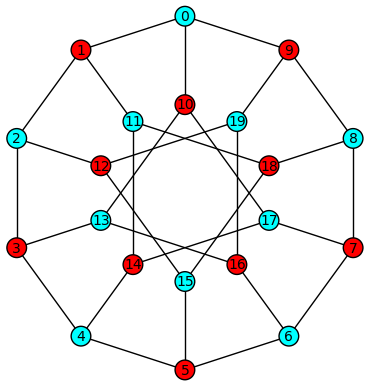

In [ ]:
G1 = Graph([(0,1), (1,2), (2,3), (3,4), (4,5), (5,6), (6,7), (7,8), (8,9), (9,0),
            (0, 10), (1,11), (2,12), (3,13), (4,14), (5,15), (6,16), (7,17), (8,18),
            (9,19),
           (10,13), (13,16), (16,19), (19,12), (12,15), (15,18), (18,11), (11,14),
           (14,17), (17,10)])

G1.graphplot(partition=mystere3(mystere1(G1, 1)), pos = pos_dict).show()

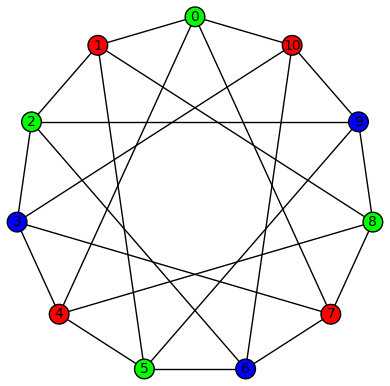

In [ ]:
G2 = Graph([(0,1), (1,2), (2,3), (3,4), (4,5), (5,6), (6,7), (7,8),(8,9),(9,10),(10,0),
           (0,4), (1,5), (2,6), (3,7),(4,8),(5,9), (6,10),(7,0),(8,1),(9,2),(10,3)])
G2.show(partition=mystere3(mystere1(G2, 1)), layout = 'circular')

1) Expliquer ce que fait chaque fonction <tt>mystere1</tt> et son objectif. Vous pouvez expliquer pour cela le rôle des deux fonctions <tt>mystere2</tt> et <tt>mystere3</tt>.

In [12]:
### Explication des fonctions :
- **`mystere2(L)`** : Calcule le plus petit entier strictement positif (Mex - Minimum Excluded Value) qui n'est pas présent dans la liste `L`.
- **`mystere3(d)`** : Convertit un dictionnaire d'association `{sommet: couleur}` en une liste de listes (partition) regroupant les sommets ayant la même couleur.
- **`mystere1(G, s)`** : Implémente l'algorithme de **coloration gloutonne** (Welsh-Powell modifié) couplé à un parcours en profondeur (DFS) pour colorier le graphe `G` en évitant que deux voisins aient la même couleur.

SyntaxError: unterminated string literal (detected at line 2) (2396192746.py, line 2)

2. Une fonction utilise un des parcours vu en cours en l'améliorant. Lequel ? Prouvez que c'est bien ce parcours en donnant l'ordre de parcours.

In [13]:
La fonction utilise un **parcours en profondeur (DFS)**, car elle utilise une pile `P` et explore le graphe en allant au plus profond d'une branche (`som = P[-1]`, `P.append(i)`) avant de revenir en arrière (`P.pop()`) lorsqu'aucun nouveau voisin non visité n'est trouvé.

SyntaxError: unterminated string literal (detected at line 1) (2101679292.py, line 1)